# Notebook 01: Dataset Inventory & Adaptive High-Focus Quality Control (QC) Audit
**Project:** `Fabric_FYP` — Quantitative Color and Texture Analysis of Degraded Cotton and Polyester Fabrics

This notebook audits all raw AmScope digital microscope images (`1228 × 922` pixels) stored in `data/raw/` across ten experimental groups:
* **Controls (Day 0):** `CC` (Cotton Control), `CP` (Polyester Control)
* **Indoor Cabin (Days 1–30):** `CI` (Cotton Indoor), `PI` (Polyester Indoor)
* **Outdoor Sites (Days 1–30):** `C1`, `C2`, `C3` (Cotton Sites 1–3) and `P1`, `P2`, `P3` (Polyester Sites 1–3)

Rather than forcing a rigid center crop, each image is evaluated using an **adaptive multi-scale Region of Interest (ROI) search** that locates the sharpest, highest-data fabric region while excluding dark corner lens vignetting.

In [1]:
import sys
import json
import importlib
import platform
from pathlib import Path
import cv2
import pandas as pd
import matplotlib.pyplot as plt

# Resolve Fabric_FYP project root dynamically
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert PROJECT_ROOT.name == "Fabric_FYP", f"Expected project root 'Fabric_FYP', got '{PROJECT_ROOT.name}'"
assert (PROJECT_ROOT / "src" / "fabric_taphonomy").is_dir(), "Missing src/fabric_taphonomy package!"

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import fabric_taphonomy.exploration as exp
importlib.reload(exp)  # Always load the latest saved version of exploration.py
from fabric_taphonomy.exploration import audit_dataset, CANDIDATE_ROI_SIZES, MIN_FOCUS_THRESHOLD

# Define standard input and output directories
RAW_DIR = PROJECT_ROOT / "data" / "raw"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
PARAMS_DIR = PROJECT_ROOT / "outputs" / "parameters"

for folder in (TABLES_DIR, FIGURES_DIR, PARAMS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300})
print("Python:", platform.python_version(), "|", sys.executable)
print("Project Root:", PROJECT_ROOT)
print("Candidate ROI Sizes:", CANDIDATE_ROI_SIZES, "| Min Focus Threshold:", MIN_FOCUS_THRESHOLD)

Python: 3.14.7 | /Users/anna/PycharmProjects/Fabric_FYP/.venv/bin/python
Project Root: /Users/anna/PycharmProjects/Fabric_FYP
Candidate ROI Sizes: [(850, 650), (750, 600), (650, 600), (600, 500), (500, 500)] | Min Focus Threshold: 5.0


## 1. Adaptive High-Focus ROI Detection & Visual Soil Quality Control (QC) Audit
Degraded woven fabrics can warp or fray unevenly under the microscope, causing certain regions of the field of view to be sharper than others. Using a sliding-window Laplacian variance search across candidate sizes (`500 × 500` up to `850 × 650` pixels) inside the vignette-free interior (`X: 140..1088`, `Y: 90..832`), the pipeline locates the optimal high-focus, high-data bounding box (`roi_x, roi_y, roi_w, roi_h`) for each image.

Rather than relying on exposure day alone, outdoor samples are evaluated objectively inside their selected ROI against the clean Day 0 control baseline (`CC` / `CP`) in perceptual **CIELAB color space** (`ΔE`, yellowing shift `Δb*`, and localized dark/yellow soil pixel percentage):

* **Grade A (Clean & Optimal):** Sharp optical focus (`focus_score ≥ 5.0`) and visually unstained fabric surface (all Day 0 controls, indoor samples, and outdoor samples without visible soil accumulation, including clean Day 2+ specimens).
* **Grade B (Outdoor Soil Stained):** Sharp optical focus (`≥ 5.0`) on outdoor samples exhibiting measurable soil staining (`ΔE ≥ 5.5`, `Δb* ≥ 3.5`, or `≥ 1.5%` soil-stained pixels). Requires a `1-px` (`3 × 3`) median filter prior to texture extraction.
* **Grade C (Blurry / Damaged):** Out-of-focus captures (`focus_score < 5.0`) or invalid dimensions/corrupted files. Excluded from analysis.

In [2]:
# Scan all raw folders, compute adaptive high-focus ROIs, and assign visual QC grades
inventory_df = audit_dataset(RAW_DIR)
inventory_df.to_csv(TABLES_DIR / "dataset_inventory.csv", index=False)

eligible_df = inventory_df.loc[inventory_df["eligible"]].copy()

# Cross-tabulation of QC Grades across Fabric Types and Group Codes
qc_summary = pd.crosstab(
    [inventory_df["fabric"], inventory_df["setting"], inventory_df["group_code"]],
    inventory_df["qc_grade"]
).reindex(columns=["A", "B", "C"], fill_value=0)

qc_summary["Eligible_A_B"] = qc_summary["A"] + qc_summary["B"]
qc_summary["Total_Images"] = qc_summary[["A", "B", "C"]].sum(axis=1)

display(qc_summary)
qc_summary.to_csv(TABLES_DIR / "qc_grade_summary.csv")

print(f"Total Images Scanned : {len(inventory_df)}")
print(f"Eligible (Grade A+B) : {len(eligible_df)} (Grade A: {(inventory_df['qc_grade']=='A').sum()}, Grade B: {(inventory_df['qc_grade']=='B').sum()})")
print(f"Rejected (Grade C)   : {(~inventory_df['eligible']).sum()}")
print("\nQC Classification Breakdown:")
print(inventory_df["qc_reason"].value_counts().to_string())

# Inspect early outdoor samples (Days 1 to 4) to verify clean Day 2+ images are graded as Grade A
print("\nEarly Outdoor Samples (Days 1–4) Visual Soil Audit:")
early_outdoor = inventory_df[(inventory_df["setting"] == "Outdoor") & (inventory_df["day"] <= 4)][
    ["image_id", "group_code", "day", "raw_delta_e", "yellow_shift", "soil_pixel_pct", "qc_grade", "qc_reason"]
]
display(early_outdoor)

assert eligible_df["image_id"].is_unique, "Duplicate image_id values found!"

qc_grade                       A   B  C  Eligible_A_B  Total_Images
fabric    setting group_code                                       
Cotton    Control CC           5   0  0             5             5
          Indoor  CI          15   0  0            15            15
          Outdoor C1           1  14  0            15            15
                  C2           6   9  0            15            15
                  C3           1  14  0            15            15
Polyester Control CP           5   0  0             5             5
          Indoor  PI          15   0  0            15            15
          Outdoor P1           0  15  0            15            15
                  P2           3  12  0            15            15
                  P3           1  14  0            15            15

Total Images Scanned : 130
Eligible (Grade A+B) : 130 (Grade A: 52, Grade B: 78)
Rejected (Grade C)   : 0

QC Classification Breakdown:
qc_reason
outdoor_soil_stained     78
clean_optimal            40
outdoor_clean_optimal    12

Early Outdoor Samples (Days 1–4) Visual Soil Audit:


,image_id,group_code,day,raw_delta_e,yellow_shift,soil_pixel_pct,qc_grade,qc_reason
6,C1_D1_1,C1,2,0.97,-0.73,0.04,A,outdoor_clean_optimal
7,C1_D2_18,C1,4,4.61,4.53,12.15,B,outdoor_soil_stained
21,C2_D1_19,C2,2,1.03,-0.59,0.03,A,outdoor_clean_optimal
22,C2_D2_15,C2,4,1.36,0.95,0.01,A,outdoor_clean_optimal
36,C3_D1_10,C3,2,1.49,-0.43,0.00,A,outdoor_clean_optimal
37,C3_D2_19,C3,4,4.20,4.12,7.36,B,outdoor_soil_stained
76,P1_D1_2,P1,2,0.18,-0.07,2.62,B,outdoor_soil_stained
77,P1_D2_6,P1,4,6.96,6.92,77.82,B,outdoor_soil_stained
91,P2_D1_15,P2,2,1.30,-0.72,0.81,A,outdoor_clean_optimal
92,P2_D2_20,P2,4,0.35,0.23,1.91,B,outdoor_soil_stained


## 2. Selected ROI Dimensions, Exposure Timeline Coverage & Parameter Export
The summary tables below show the distribution of variable ROI sizes selected across the dataset (confirming how often larger `850 × 650` windows vs. tighter high-focus windows were chosen) and verify sample counts across Exposure Days `0` to `30`. All per-image crop coordinates are stored in `dataset_inventory.csv` and global settings are saved to `roi_preprocessing_config.json`.

In [3]:
# 1. Inspect distribution of variable ROI dimensions selected for eligible images
roi_size_summary = (
    eligible_df.groupby(["fabric", "qc_grade", "roi_w", "roi_h"])
    .agg(
        image_count=("image_id", "count"),
        mean_focus_score=("focus_score", "mean")
    )
    .round(2)
    .reset_index()
)
display(roi_size_summary)
roi_size_summary.to_csv(TABLES_DIR / "adaptive_roi_summary.csv", index=False)

# 2. Check sample counts across Exposure Days (Days 0 to 30)
day_coverage = pd.crosstab(
    [eligible_df["fabric"], eligible_df["group_code"]],
    eligible_df["day"]
)
display(day_coverage)
day_coverage.to_csv(TABLES_DIR / "exposure_day_coverage.csv")

# 3. Export global preprocessing parameters for Notebook 02
roi_config = {
    "project_name": "Fabric_FYP",
    "crop_mode": "adaptive_variable_high_focus",
    "raw_width_px": 1228,
    "raw_height_px": 922,
    "vignette_margin_x": 140,
    "vignette_margin_y": 90,
    "candidate_roi_sizes": CANDIDATE_ROI_SIZES,
    "min_focus_threshold": MIN_FOCUS_THRESHOLD,
    "median_filter_ksize_grade_b": 3
}

config_path = PARAMS_DIR / "roi_preprocessing_config.json"
with open(config_path, "w") as f:
    json.dump(roi_config, f, indent=2)

print("Saved adaptive preprocessing configuration to:", config_path)

,fabric,qc_grade,roi_w,roi_h,image_count,mean_focus_score
0,Cotton,A,600,500,1,18.43
1,Cotton,A,850,650,27,12.89
2,Cotton,B,600,500,17,61.18
3,Cotton,B,750,600,1,83.53
4,Cotton,B,850,650,19,33.26
5,Polyester,A,600,500,19,31.77
6,Polyester,A,850,650,5,22.74
7,Polyester,B,500,500,1,39.91
8,Polyester,B,600,500,36,65.38
9,Polyester,B,850,650,4,37.44


day                   0   2   4   6   8   10  12  14  16  18  20  22  24  26  \
fabric    group_code                                                           
Cotton    C1           0   1   1   1   1   1   1   1   1   1   1   1   1   1   
          C2           0   1   1   1   1   1   1   1   1   1   1   1   1   1   
          C3           0   1   1   1   1   1   1   1   1   1   1   1   1   1   
          CC           5   0   0   0   0   0   0   0   0   0   0   0   0   0   
          CI           0   1   1   1   1   1   1   1   1   1   1   1   1   1   
Polyester CP           5   0   0   0   0   0   0   0   0   0   0   0   0   0   
          P1           0   1   1   1   1   1   1   1   1   1   1   1   1   1   
          P2           0   1   1   1   1   1   1   1   1   1   1   1   1   1   
          P3           0   1   1   1   1   1   1   1   1   1   1   1   1   1   
          PI           0   1   1   1   1   1   1   1   1   1   1   1   1   1   

day                   28  30  
fabric    group_code          
Cotton    C1           1   1  
          C2           1   1  
          C3           1   1  
          CC           0   0  
          CI           1   1  
Polyester CP           0   0  
          P1           1   1  
          P2           1   1  
          P3           1   1  
          PI           1   1

Saved adaptive preprocessing configuration to: /Users/anna/PycharmProjects/Fabric_FYP/outputs/parameters/roi_preprocessing_config.json


## 3. Visual Verification of Adaptive High-Focus ROI Boxes
To verify that the adaptive search avoids dark corner vignetting and targets sharp, representative fabric weave regions, sample images across QC grades are displayed below with their custom variable ROI bounding boxes (`roi_x, roi_y, roi_w, roi_h`) drawn in dashed yellow.

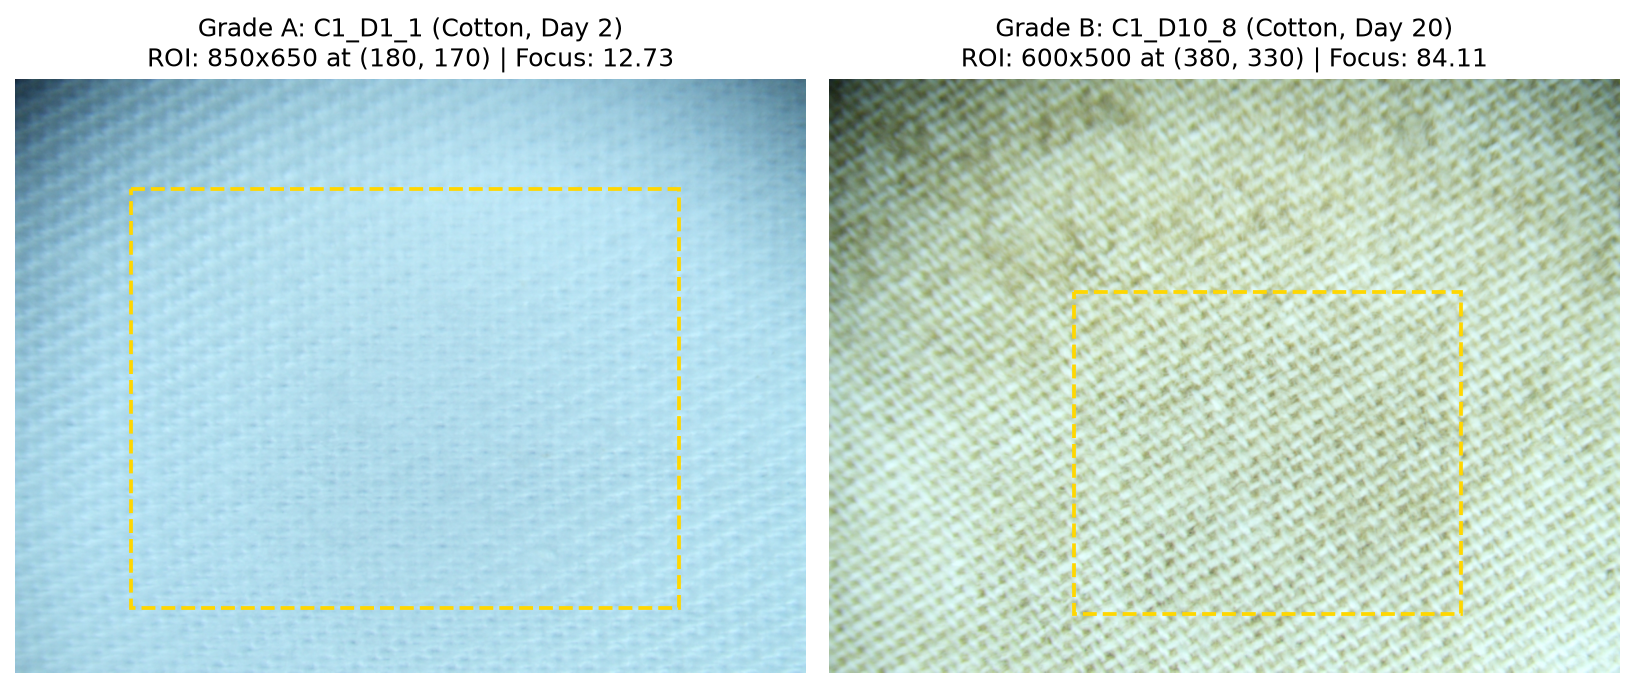

Saved visual QC verification figure to: /Users/anna/PycharmProjects/Fabric_FYP/outputs/figures/qc_grade_examples.png


In [4]:
import matplotlib.patches as patches

present_grades = [g for g in ["A", "B", "C"] if g in inventory_df["qc_grade"].values]
fig, axes = plt.subplots(1, len(present_grades), figsize=(5.5 * len(present_grades), 4.5))

if len(present_grades) == 1:
    axes = [axes]

for ax, grade in zip(axes, present_grades):
    sample = inventory_df[inventory_df["qc_grade"] == grade].iloc[0]
    img_bgr = cv2.imread(str(RAW_DIR / sample["rel_path"]))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    ax.imshow(img_rgb)
    # Draw the image's custom variable ROI bounding box
    rect = patches.Rectangle(
        (sample["roi_x"], sample["roi_y"]),
        sample["roi_w"],
        sample["roi_h"],
        linewidth=1.8, edgecolor="gold", facecolor="none", linestyle="--"
    )
    ax.add_patch(rect)
    ax.set_title(
        f"Grade {grade}: {sample['image_id']} ({sample['fabric']}, Day {sample['day']})\n"
        f"ROI: {sample['roi_w']}x{sample['roi_h']} at ({sample['roi_x']}, {sample['roi_y']}) | Focus: {sample['focus_score']}"
    )
    ax.axis("off")

plt.tight_layout()
fig_path = FIGURES_DIR / "qc_grade_examples.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print("Saved visual QC verification figure to:", fig_path)